In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#ne pas

# 1. Chargement et Split

## 1.1 Chargement

### 1.1.1 Regression 

In [43]:
df = pd.read_parquet('../data/processed/2026-10-12_132605/59.parquet')
df.head()

,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,score_ban,surface_habitable_immeuble,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,statut_geocodage,...,provenance_id_rnb,id_rnb,nombre_niveau_immeuble,appartement_non_visite,qualite_isolation_plancher_haut_comble_amenage,surface_ventilee,type_ventilation,origine,latitude,longitude
0,Installation de chauffage simple,1007.6,Réseau de chaleur isolé,0.74,6906.0,301.6,8.8,6.4,158.7,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.629216,3.005483
1,Installation de chauffage simple,3556.9,Chaudière gaz à condensation après 2015,0.59,NaN,599.6,8.5,37.8,315.6,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.371726,3.194996
2,Installation de chauffage simple,7042.0,Ballon électrique à accumulation vertical Caté...,0.65,NaN,0.0,33.4,29.7,0.0,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.364151,3.533716
3,Installation de chauffage simple,22052.5,Chaudière gaz à condensation 1986-2000,0.68,NaN,579.4,111.4,62.3,305.0,adresse géocodée ban à l'adresse,...,Logiciel,MV6BVK19M4BV,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.26472,3.957959
4,Installation de chauffage simple,5982.0,Chaudière gaz à condensation après 2015,0.53,NaN,1243.3,23.3,45.9,654.3,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.039473,3.29219


In [44]:
# variables calculées à partir de la conso (sorties du calcul DPE) -> fuite de données pour les 2 cibles
# conso_* : consommations, cout_* : coûts (= conso x prix), emission_ges_* : émissions (= conso x facteur),
# besoin_* : besoins énergétiques (conso = besoin / rendement), etiquette_* : étiquettes DPE et GES
fuite_list = [col for col in df.columns if col.startswith(('conso_', 'cout_', 'emission_ges', 'besoin_', 'etiquette_'))]
print(len(fuite_list))
fuite_list

54


['conso_chauffage_installation_chauffage_n1',
 'conso_auxiliaires_ep',
 'cout_eclairage',
 'conso_auxiliaires_ef',
 'cout_chauffage',
 'conso_5_usages_par_m2_ep',
 'conso_ecs_ef_energie_n1',
 'conso_ecs_ef_energie_n2',
 'emission_ges_chauffage',
 'conso_5_usages_par_m2_ef',
 'cout_ecs_energie_n2',
 'conso_chauffage_ef_energie_n1',
 'conso_chauffage_ef_energie_n2',
 'cout_total_5_usages_energie_n2',
 'cout_total_5_usages_energie_n1',
 'cout_ecs_energie_n1',
 'conso_chauffage_generateur_n1_installation_n1',
 'emission_ges_eclairage',
 'emission_ges_ecs',
 'conso_5_usages_ef_energie_n2',
 'conso_5_usages_ef',
 'conso_5_usages_ef_energie_n1',
 'conso_5_usages_ep',
 'besoin_ecs',
 'cout_ecs',
 'emission_ges_5_usages_energie_n1',
 'emission_ges_5_usages_energie_n2',
 'emission_ges_5_usages_par_m2',
 'cout_auxiliaires',
 'besoin_chauffage',
 'emission_ges_refroidissement',
 'conso_chauffage_ef',
 'conso_ecs_ep',
 'conso_ecs_ef',
 'emission_ges_5_usages',
 'etiquette_ges',
 'conso_ef_installat

In [45]:
conso_list = [col for col in df.columns if col.startswith('conso')]

On a 32 variables de conso, on va juste garder `conso_5_usages_par_m2_ef` et retirer les autres pour éviter la fuites de données 

In [46]:
y_conso = df["conso_5_usages_par_m2_ef"]
X_conso = df.drop(columns=conso_list)

### 1.1.2 Classification

In [47]:
dpe_list = [col for col in df.columns if col.endswith('dpe')]

In [48]:
dpe_list

['date_etablissement_dpe',
 'date_reception_dpe',
 'modele_dpe',
 'date_fin_validite_dpe',
 'version_dpe',
 'date_derniere_modification_dpe',
 'etiquette_dpe',
 'methode_application_dpe',
 'numero_dpe']

In [49]:
df[["etiquette_dpe","numero_dpe"]].head(10)

,etiquette_dpe,numero_dpe
0,C,2659E0039476U
1,C,2659E0007955L
2,D,2659E0077741N
3,E,2659E0079133B
4,C,2659E0000267T
5,C,2659E0012708G
6,C,2659E0044677V
7,E,2659E0023285B
8,E,2659E0060211H
9,E,2659E0047310C


In [50]:
y_dpe = df["etiquette_dpe"]
X_dpe = df.drop(columns="etiquette_dpe")

### 1.1.3 Variables supprimées

On garde uniquement les caractéristiques physiques du logement et de ses équipements (surfaces, isolation, déperditions, chauffage, ECS, ventilation...). Les mêmes colonnes sont retirées pour les 2 cibles :

- **Fuite de données** (`fuite_list`, 54 colonnes) : `conso_*`, `cout_*`, `emission_ges_*`, `besoin_*` et `etiquette_*` sont des sorties du calcul DPE. L'étiquette est calculée à partir de la conso et des émissions, et les coûts / émissions sont la conso multipliée par un prix ou un facteur. Les garder revient à donner la réponse au modèle.
- **Identifiants** (`id_list`) : `numero_dpe`, `_id`, `_i`, `_rand`, `identifiant_ban`, `id_rnb`. Une valeur unique (ou presque) par ligne, aucun pouvoir prédictif, le modèle ne peut que les apprendre par cœur.
- **Adresses et localisation** (`localisation_list`) : adresses en texte libre (jusqu'à 92 000 modalités, qui font exploser le OneHotEncoder), codes postaux, communes, coordonnées, et la qualité du géocodage (`score_ban`, `statut_geocodage`). On veut prédire à partir du logement, pas de son emplacement. `zone_climatique` et `classe_altitude` sont gardées : ce sont des entrées officielles du calcul DPE avec peu de modalités.
- **Descriptions** (`description_list`) : `description_*` sont du texte libre (jusqu'à 5 400 modalités) qui répète l'information déjà présente dans les colonnes `type_*`.
- **Informations sur le diagnostic** (`info_dpe_list`) : `modele_dpe`, `version_dpe`, `methode_application_dpe`, `origine`, `provenance_id_rnb`, `appartement_non_visite`. Elles décrivent comment le DPE a été réalisé, pas le logement. Le caractère neuf / existant reste porté par `annee_construction` et `periode_construction`, et maison / appartement par `type_batiment`.
- **Dates du diagnostic** (`date_list`) : `date_etablissement_dpe`, `date_reception_dpe`, `date_visite_diagnostiqueur` (quasi identiques entre elles), `date_fin_validite_dpe` (= établissement + 10 ans) et `date_derniere_modification_dpe` (date technique de la base). Tous les DPE sont postérieurs à la réforme de juillet 2021, donc la date n'apporte rien sur le logement, et en texte elles seraient encodées en ~1 500 colonnes chacune. L'âge du logement reste porté par `annee_construction` et `periode_construction`.

In [51]:
# on retire les identifiants et les variables qui fuient (cf. fuite_list) avant le split
id_list = ['numero_dpe', '_id', '_i', '_rand', 'identifiant_ban', 'id_rnb']
# adresses et localisation : texte libre ou codes géographiques, pas des caractéristiques du logement
localisation_list = ['adresse_ban', 'adresse_brut', 'adresse_complete_brut', 'complement_adresse_batiment',
                     'complement_adresse_logement', 'nom_rue_ban', 'numero_voie_ban',
                     'code_postal_ban', 'code_postal_brut', 'code_insee_ban', 'nom_commune_ban', 'nom_commune_brut',
                     'code_departement_ban', 'code_region_ban', 'coordonnee_cartographique_x_ban',
                     'coordonnee_cartographique_y_ban', 'latitude', 'longitude', 'score_ban', 'statut_geocodage']
# descriptions en texte libre, redondantes avec les colonnes type_*
description_list = [col for col in df.columns if col.startswith('description_')]
# informations sur le diagnostic lui-même, pas sur le logement
info_dpe_list = ['modele_dpe', 'version_dpe', 'methode_application_dpe', 'origine', 'provenance_id_rnb',
                 'appartement_non_visite']
# dates du diagnostic (l'âge du logement reste dans annee_construction / periode_construction)
date_list = ['date_etablissement_dpe', 'date_reception_dpe', 'date_fin_validite_dpe',
             'date_visite_diagnostiqueur', 'date_derniere_modification_dpe']
drop_list = fuite_list + id_list + localisation_list + description_list + info_dpe_list + date_list
X_dpe = df.drop(columns=drop_list)
X_conso = df.drop(columns=drop_list)
print(f"shape X_dpe: {X_dpe.shape}, X_conso: {X_conso.shape}")

shape X_dpe: (138807, 64), X_conso: (138807, 64)


## 1.2 Split

On prend 70 / 30 pour train / test

In [52]:
X_dpe_train, X_dpe_test, y_dpe_train, y_dpe_test = train_test_split(X_dpe, y_dpe, test_size=0.3, random_state=42)
X_conso_train, X_conso_test, y_conso_train, y_conso_test = train_test_split(X_conso, y_conso, test_size=0.3, random_state=42)

In [53]:
print(f"shape train dpe: {X_dpe_train.shape}, test dpe: {X_dpe_test.shape}")
print(f"shape train conso: {X_conso_train.shape}, test conso: {X_conso_test.shape}")

shape train dpe: (97164, 64), test dpe: (41643, 64)
shape train conso: (97164, 64), test conso: (41643, 64)


In [54]:
print(f"nb de données qualitatives dpe: {X_dpe_train.select_dtypes(include='object').columns.size}")
print(f"nb de données qualitatives conso: {X_conso_train.select_dtypes(include='object').columns.size}")  

print(f"nb de données quantitatives dpe: {X_dpe_train.select_dtypes(include='number').columns.size}")
print(f"nb de données quantitatives conso: {X_conso_train.select_dtypes(include='number').columns.size}")  

nb de données qualitatives dpe: 31
nb de données qualitatives conso: 31
nb de données quantitatives dpe: 33
nb de données quantitatives conso: 33


/tmp/ipykernel_22486/1010822538.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"nb de données qualitatives dpe: {X_dpe_train.select_dtypes(include='object').columns.size}")
/tmp/ipykernel_22486/1010822538.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-

In [55]:
quant_cols_dpe = X_dpe.select_dtypes(include='number').columns
quali_cols_dpe = X_dpe.select_dtypes(exclude='number').columns

## 1.3 Imputer

Possibilité : SimpleImputer (+ fréquent / médiane), pas possible les autres imputer pck on a pas que du numérique...

In [56]:
from sklearn.impute import SimpleImputer


In [57]:
quanti_imputer = SimpleImputer(strategy='median')
quali_imputer = SimpleImputer(strategy='most_frequent')

## 1.4 Scaler / Encoder

In [58]:
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown='ignore')    

## 1.5 Sélection de variable

en fonction du modèle qu'on choisira, il faudra peut être en rajouter...

In [59]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest

In [60]:
var = VarianceThreshold()
select_k_best = SelectKBest(k=20) #il faudra trouver le bon k pour la sélection des features

```python
# Le nombre de variables k se règle comme un hyperparamètre
param_grid = {"selection__k": [10, 20, 50, "all"]}
search = GridSearchCV(pipe, param_grid, cv=5, scoring="f1")
```

il faudra ajouter ça pour chercher le bon K

## 1.5 Model

### 1.5.1 Classification

Pour l'étiquette DPE, on peut tester: logisticregression, randomforest, linearSVC, 

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

preprocess_dpe = ColumnTransformer([
    ("quanti", Pipeline([("imputer", quanti_imputer), ("scaler", scaler)]), quant_cols_dpe),
    ("quali", Pipeline([("imputer", quali_imputer), ("encoder", encoder)]), quali_cols_dpe),
])

pipe_dpe = Pipeline([
    ("preprocess", preprocess_dpe),
    ("variance", var),
    ("selection", select_k_best),
    ("model", LogisticRegression(max_iter=1000)),
    ]   
)

param_grid = {"selection__k": [10, 20, 50, "all"]}
search_dpe = GridSearchCV(pipe_dpe, param_grid, cv=2, scoring="f1_macro", n_jobs=-1)
search_dpe.fit(X_dpe_train, y_dpe_train)

print(search_dpe.best_params_)
print(classification_report(y_dpe_test, search_dpe.predict(X_dpe_test)))

{'selection__k': 'all'}
              precision    recall  f1-score   support

           A       0.85      0.87      0.86      2301
           B       0.62      0.31      0.41      2900
           C       0.77      0.82      0.80     14822
           D       0.61      0.69      0.65     11084
           E       0.52      0.54      0.53      6572
           F       0.54      0.30      0.39      2610
           G       0.66      0.55      0.60      1354

    accuracy                           0.67     41643
   macro avg       0.65      0.58      0.61     41643
weighted avg       0.66      0.67      0.66     41643



In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

# on garde le k trouvé par le GridSearch de la LogisticRegression ci-dessus
best_k = search_dpe.best_params_["selection__k"]

# LinearSVC retiré : moins bon que les 2 autres (f1_macro 0.52) et ~350 s par fit
modeles_dpe = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

resultats_dpe = []
for nom, modele in modeles_dpe.items():
    pipe = Pipeline([
        ("preprocess", preprocess_dpe),
        ("variance", var),
        ("selection", SelectKBest(k=best_k)),
        ("model", modele),
    ])
    cv = cross_validate(pipe, X_dpe_train, y_dpe_train, cv=3, scoring=["f1_macro", "accuracy"])
    resultats_dpe.append({
        "modele": nom,
        "f1_macro": cv["test_f1_macro"].mean(),
        "accuracy": cv["test_accuracy"].mean(),
        "temps_fit (s)": cv["fit_time"].mean(),
    })

pd.DataFrame(resultats_dpe).sort_values("f1_macro", ascending=False).set_index("modele").round(3)

,f1_macro,accuracy,temps_fit (s)
modele,,,
RandomForest,0.728,0.775,48.727
LogisticRegression,0.599,0.667,46.171


In [67]:
# recherche des hyperparamètres du RandomForest (meilleur modèle de la comparaison)
# 8 combinaisons x 2 plis = 16 fits (~45 s chacun)
pipe_rf = Pipeline([
    ("preprocess", preprocess_dpe),
    ("variance", var),
    ("selection", SelectKBest(k=best_k)),
    ("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
])

param_grid_rf = {
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 5],
    "model__class_weight": [None, "balanced"],  # "balanced" pour aider les classes rares (B, F, G)
}
search_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=2, scoring="f1_macro", return_train_score=True)
search_rf.fit(X_dpe_train, y_dpe_train)

print(search_rf.best_params_)
# écart train / CV : un score train proche de 1 est normal pour un RandomForest, ce qui compte c'est le score CV / test
print(f"f1_macro train: {search_rf.cv_results_['mean_train_score'][search_rf.best_index_]:.3f}")
print(f"f1_macro CV: {search_rf.best_score_:.3f}")
print(classification_report(y_dpe_test, search_rf.predict(X_dpe_test)))

{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 1}
f1_macro train: 0.980
f1_macro CV: 0.735
              precision    recall  f1-score   support

           A       0.95      0.95      0.95      2301
           B       0.77      0.83      0.80      2900
           C       0.92      0.82      0.86     14822
           D       0.72      0.79      0.76     11084
           E       0.65      0.72      0.68      6572
           F       0.61      0.57      0.59      2610
           G       0.77      0.66      0.71      1354

    accuracy                           0.78     41643
   macro avg       0.77      0.76      0.77     41643
weighted avg       0.79      0.78      0.79     41643



In [68]:
# max_depth et min_samples_leaf sont déjà au réglage le plus permissif : on les fixe
# et on cherche sur le nombre d'arbres et le nombre de variables testées à chaque découpage
# 4 combinaisons x 2 plis = 8 fits, plus longs que la grille précédente (plus d'arbres / de variables)
pipe_rf.set_params(**search_rf.best_params_)

param_grid_rf2 = {
    "model__n_estimators": [100, 300],
    "model__max_features": ["sqrt", 0.3],
}
search_rf2 = GridSearchCV(pipe_rf, param_grid_rf2, cv=2, scoring="f1_macro", return_train_score=True)
search_rf2.fit(X_dpe_train, y_dpe_train)

print(search_rf2.best_params_)
print(f"f1_macro train: {search_rf2.cv_results_['mean_train_score'][search_rf2.best_index_]:.3f}")
print(f"f1_macro CV: {search_rf2.best_score_:.3f}")
print(classification_report(y_dpe_test, search_rf2.predict(X_dpe_test)))

pd.DataFrame(search_rf2.cv_results_)[["params", "mean_train_score", "mean_test_score", "mean_fit_time"]].round(3)

{'model__max_features': 0.3, 'model__n_estimators': 300}
f1_macro train: 0.979
f1_macro CV: 0.766
              precision    recall  f1-score   support

           A       0.95      0.95      0.95      2301
           B       0.77      0.84      0.80      2900
           C       0.93      0.85      0.89     14822
           D       0.79      0.82      0.80     11084
           E       0.71      0.76      0.74      6572
           F       0.65      0.67      0.66      2610
           G       0.78      0.72      0.75      1354

    accuracy                           0.82     41643
   macro avg       0.80      0.80      0.80     41643
weighted avg       0.82      0.82      0.82     41643



,params,mean_train_score,mean_test_score,mean_fit_time
0,"{'model__max_features': 'sqrt', 'model__n_esti...",0.980,0.735,25.667
1,"{'model__max_features': 'sqrt', 'model__n_esti...",0.981,0.741,73.766
2,"{'model__max_features': 0.3, 'model__n_estimat...",0.978,0.763,62.471
3,"{'model__max_features': 0.3, 'model__n_estimat...",0.979,0.766,173.309


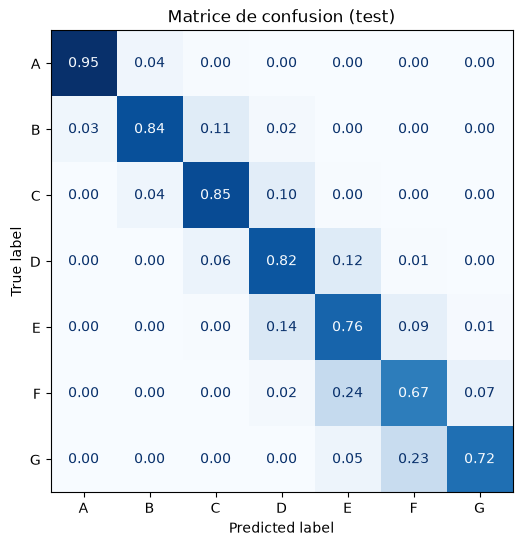

prédictions exactes: 0.817
prédictions à une classe près: 0.989


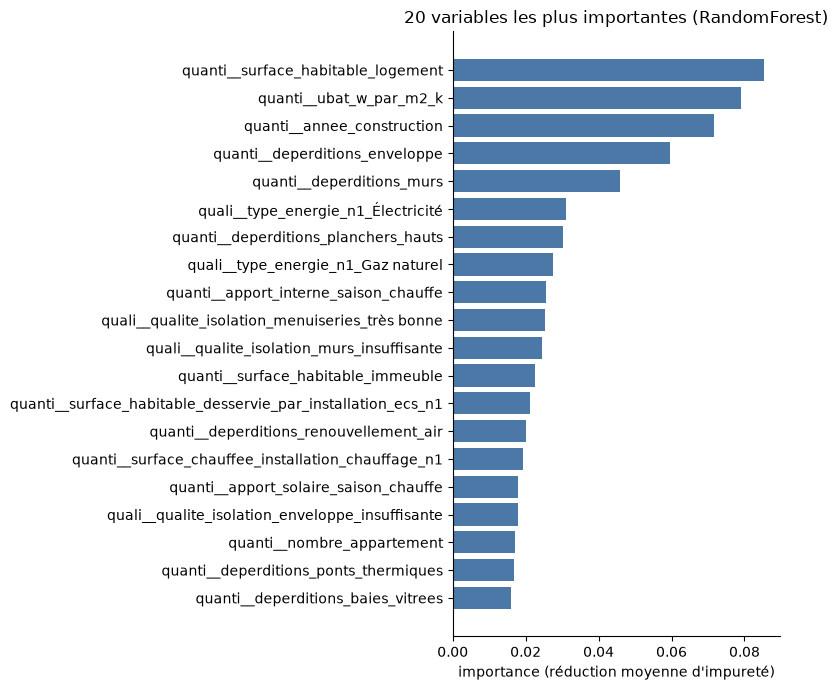

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_rf = search_rf2.best_estimator_
y_dpe_pred = best_rf.predict(X_dpe_test)

# matrice de confusion normalisée par ligne : chaque ligne = rappel de la vraie classe
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_dpe_test, y_dpe_pred, normalize="true", values_format=".2f",
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matrice de confusion (test)")
plt.show()

ecart = (y_dpe_test.map(ord) - pd.Series(y_dpe_pred, index=y_dpe_test.index).map(ord)).abs()
print(f"prédictions exactes: {(ecart == 0).mean():.3f}")
print(f"prédictions à une classe près: {(ecart <= 1).mean():.3f} <= en gros c'est à quel point on est proche de la bonne classe (genre si on a A, à quel point on est bon ou pas par rapport à B ou C)")



#importances variables
noms_variables = best_rf[:-1].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=noms_variables)
top_importances = importances.sort_values().tail(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_importances.index, top_importances.values, color="#4C78A8")
ax.set_title("20 variables les plus importantes (RandomForest)")
ax.set_xlabel("importance (réduction moyenne d'impureté)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Pour la consommation, on peut tester: linearregression, lasso (mais on a déjà la selection donc jsp), elasticnet, randomforestregressor, gradient mais flemme...

### 1.5.2 Regrsesion